# 📊 Análisis Exploratorio de Datos (EDA) — Clasificación Semántica Zero-Shot / Prototípica (2010–2023)

Este notebook realiza la **auditoría y exploración del conjunto de datos procesado (capa Silver)** resultante del pipeline de categorización semántica y filtrado de ruido (`src/articulos/etl_categorizacion.py`):
- **Origen en Data Lake (Cloudflare R2 / S3):** `processed/huggingface/multisource_bancos_2010_2023.parquet`.
- **Universo de estudio:** Los 6 grandes bancos de EE. UU. (**US Big 6**: `JPM`, `BAC`, `WFC`, `C`, `GS`, `MS`).
- **Modelo de clasificación aplicado:** Bi-Encoder `sentence-transformers/all-MiniLM-L6-v2` con centroides prototípicos, extracción guiada de fragmentos (`process_text`), desambiguación de rol de analista y umbrales adaptativos.

### Objetivos del EDA:
1. **Inspección Estructural y Esquema Silver:** Verificar dimensiones, tipos de datos, ausencia de nulos críticos y poda de columnas crudas.
2. **Balance Señal vs. Ruido (`is_ruido`):** Cuantificar la proporción de noticias financieras relevantes frente al ruido descartado globalmente y por entidad bancaria.
3. **Distribución de Categorías Temáticas (`category`) y Confianza (`confianza`):** Evaluar el reparto entre *Earnings*, *M&A*, *Macro*, *Legal*, *Credit*, *Governance* y *Ruido*, así como la distribución estadística del score de similitud coseno.
4. **Cobertura Temporal Post-Filtrado (2010–2023):** Comprobar la densidad anual de noticias limpias por banco tras descartar el ruido para garantizar series continuas hacia la fase de sentimiento con **FinBERT**.

In [1]:
# 1. Configuración del entorno y carga del dataset categorizado (Capa Silver) desde S3/R2 o backup local

import sys
from pathlib import Path
import pandas as pd
import numpy as np
import pyarrow.parquet as pq
import pyarrow.fs as fs
from IPython.display import display

# Resolver ruta hacia 'src' para importar módulos de configuración del proyecto
CURRENT_DIR = Path.cwd().resolve()
SRC_PATH = str(CURRENT_DIR.parent) if CURRENT_DIR.name == "notebooks" else str(CURRENT_DIR / "src")
if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

from config.settings import settings

# Columnas esperadas en el dataset procesado (capa Silver)
COLS = [
    "ticker", "company_name", "cik", "date", "datetime",
    "title", "article", "ticker_count", "is_multisubject",
    "process_text", "category", "confianza", "is_ruido"
]

def cargar_parquet_lazy() -> pd.DataFrame:
    """Descarga y carga el dataset categorizado desde Cloudflare R2 / S3 (o backup local si existe)."""
    # Comprobar primero si existe el backup local generado por etl_categorizacion.py
    local_candidates = [
        Path("data/processed_multisource_bancos_2010_2023.parquet"),
        Path("../../data/processed_multisource_bancos_2010_2023.parquet"),
        Path("../data/processed_multisource_bancos_2010_2023.parquet"),
    ]
    ruta_local = next((p for p in local_candidates if p.exists()), None)

    if ruta_local:
        print(f"Cargando dataset local desde [{ruta_local}]...")
        return pd.read_parquet(ruta_local, columns=COLS)

    # Configurar el sistema de archivos S3 utilizando las credenciales de settings
    s3_fs = fs.S3FileSystem(
        access_key=settings.aws_access_key_id,
        secret_key=settings.aws_secret_access_key,
        endpoint_override=settings.s3_endpoint_url,
        region=settings.s3_region
    )

    file_path = f"{settings.s3_bucket_name}/processed/huggingface/multisource_bancos_2010_2023.parquet"

    print(f"Leyendo metadatos y dataset desde S3/R2 [{file_path}] con PyArrow S3FileSystem...")
    table = pq.read_table(file_path, filesystem=s3_fs, columns=COLS)
    return table.to_pandas()

# Ejecutar la carga y mostrar diagnóstico inicial
df = cargar_parquet_lazy()
print(f"Dataset cargado exitosamente: {df.shape[0]:,} registros x {df.shape[1]} columnas.")
display(df.head())

Leyendo metadatos y dataset desde S3/R2 [tfm-master-prediccion-bancos-usa/processed/huggingface/multisource_bancos_2010_2023.parquet] con PyArrow S3FileSystem...
Dataset cargado exitosamente: 89,846 registros x 13 columnas.


,ticker,company_name,cik,date,datetime,title,article,ticker_count,is_multisubject,process_text,category,confianza,is_ruido
0,BAC,Bank of America Corp /DE/,CIK0000070858,2010-01-02 02:16:00,2010-01-02 02:16:00+00:00,Stocks may struggle with less government support,Economic data in early January may test recove...,3,True,Economic data in early January may test recove...,macro,37.36,True
1,JPM,JPMorgan Chase & Co.,CIK0000019617,2010-01-02 02:16:00,2010-01-02 02:16:00+00:00,Stocks may struggle with less government support,Economic data in early January may test recove...,3,True,Economic data in early January may test recove...,macro,37.36,True
2,WFC,Wells Fargo & Company/MN,CIK0000072971,2010-01-02 02:16:00,2010-01-02 02:16:00+00:00,Stocks may struggle with less government support,Economic data in early January may test recove...,3,True,Economic data in early January may test recove...,macro,37.36,True
3,GS,Goldman Sachs Group Inc.,CIK0000886982,2010-01-02 12:45:00,2010-01-02 12:45:00+00:00,Preview,A look forward to those events scheduled for n...,1,False,A look forward to those events scheduled for n...,ruido,27.86,True
4,JPM,JPMorgan Chase & Co.,CIK0000019617,2010-01-02 12:45:00,2010-01-02 12:45:00+00:00,How to Bet on Health and Wealth,Why health care and banking are good bets in 2...,3,True,Why health care and banking are good bets in 2...,m&a,30.26,True


---
## 1. Normalización Temporal y Balance Global: Datos que Sirven (`is_ruido == False`) vs. Datos que No Sirven (`is_ruido == True`)

En esta celda realizamos tres tareas fundamentales antes de construir las matrices de cobertura:
1. **Estandarización de Fechas:** Convertimos la columna `datetime` a formato `UTC` y extraemos el año (`year`) acotando estrictamente la ventana de estudio **2010–2023**.
2. **Partición Señal vs. Ruido:** Dividimos el dataset en dos subconjuntos disjuntos según la decisión del clasificador semántico:
   - `df_util` (`is_ruido == False`): Noticias con señal financiera legítima que alimentarán a **FinBERT**.
   - `df_ruido` (`is_ruido == True`): Noticias descartadas (rol de analista sobre terceros, ticker bleed sin saliencia de entidad, baja confianza semántica o temática fuera de dominio).
3. **Tabla de Balance por Banco:** Cuantificamos cuántas noticias útiles y cuántas de ruido tiene cada uno de los 6 bancos (`BAC`, `C`, `GS`, `JPM`, `MS`, `WFC`), junto con su tasa de retención (`% Útil`).

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética general para los gráficos del EDA
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.figsize": (12, 6), "font.size": 11})

# 1. Normalización de la columna temporal y extracción del año
df["dt_parsed"] = pd.to_datetime(df["datetime"], utc=True, errors="coerce")
nulos_fecha = df["dt_parsed"].isna().sum()
print(f"Nulos en fecha tras parseo UTC: {nulos_fecha:,}")

df_valid = df.dropna(subset=["dt_parsed"]).copy()
df_valid["year"] = df_valid["dt_parsed"].dt.year

# Filtrar estrictamente al horizonte del TFM (2010-2023)
df_2010_2023 = df_valid[(df_valid["year"] >= 2010) & (df_valid["year"] <= 2023)].copy()

# 2. Separar los datos que SIRVEN (is_ruido == False) de los que NO SIRVEN (is_ruido == True)
df_util = df_2010_2023[~df_2010_2023["is_ruido"]].copy()
df_ruido = df_2010_2023[df_2010_2023["is_ruido"]].copy()

# Publicar/sincronizar el nuevo subconjunto útil (df_util_v2.parquet) en Cloudflare R2
import pyarrow as pa
s3_fs_util = fs.S3FileSystem(
    access_key=settings.aws_access_key_id,
    secret_key=settings.aws_secret_access_key,
    endpoint_override=settings.s3_endpoint_url,
    region=settings.s3_region
)
R2_UTIL_V2_PATH = f"{settings.s3_bucket_name}/processed/huggingface/df_util/df_util_v2.parquet"
df_util_export = df_util.drop(columns=["dt_parsed"], errors="ignore")
pq.write_table(pa.Table.from_pandas(df_util_export, preserve_index=False), R2_UTIL_V2_PATH, filesystem=s3_fs_util, compression="zstd")
print(f"✔ Nuevo dataset útil sincronizado en R2: [{R2_UTIL_V2_PATH}] ({len(df_util_export):,} filas).")

total_noticias = len(df_2010_2023)
print("=" * 75)
print(f"RESUMEN GLOBAL EN VENTANA 2010-2023: {total_noticias:,} noticias")
print("-" * 75)
print(f"✔ Datos que SIRVEN (Señal / is_ruido=False) : {len(df_util):>7,} ({len(df_util) / total_noticias * 100:.2f}%)")
print(f"✖ Datos que NO SIRVEN (Ruido / is_ruido=True): {len(df_ruido):>7,} ({len(df_ruido) / total_noticias * 100:.2f}%)")
print("=" * 75)

# 3. Resumen desglosado por entidad bancaria
balance_bancos = (
    df_2010_2023.groupby("ticker")
    .agg(
        Banco=("company_name", "first"),
        Total_Noticias=("title", "count"),
        Noticias_Utiles=("is_ruido", lambda s: int((~s).sum())),
        Noticias_Ruido=("is_ruido", lambda s: int(s.sum())),
        Confianza_Media_Util=("confianza", lambda s: round(s[~df_2010_2023.loc[s.index, "is_ruido"]].mean(), 2))
    )
    .reset_index()
)
balance_bancos["% Señal Útil"] = ((balance_bancos["Noticias_Utiles"] / balance_bancos["Total_Noticias"]) * 100).round(2)
balance_bancos["% Ruido"] = ((balance_bancos["Noticias_Ruido"] / balance_bancos["Total_Noticias"]) * 100).round(2)
balance_bancos = balance_bancos.sort_values(by="Noticias_Utiles", ascending=False).reset_index(drop=True)

display(balance_bancos)

Nulos en fecha tras parseo UTC: 0
RESUMEN GLOBAL EN VENTANA 2010-2023: 89,846 noticias
---------------------------------------------------------------------------
✔ Datos que SIRVEN (Señal / is_ruido=False) :  27,217 (30.29%)
✖ Datos que NO SIRVEN (Ruido / is_ruido=True):  62,629 (69.71%)


,ticker,Banco,Total_Noticias,Noticias_Utiles,Noticias_Ruido,Confianza_Media_Util,% Señal Útil,% Ruido
0,WFC,Wells Fargo & Company/MN,16075,5349,10726,48.60,33.28,66.72
1,MS,Morgan Stanley,16341,5289,11052,46.90,32.37,67.63
2,GS,Goldman Sachs Group Inc.,18321,5113,13208,48.25,27.91,72.09
3,JPM,JPMorgan Chase & Co.,18953,4362,14591,47.28,23.01,76.99
4,C,Citigroup Inc.,8647,4251,4396,49.91,49.16,50.84
5,BAC,Bank of America Corp /DE/,11509,2853,8656,47.89,24.79,75.21


---
## 2. Mapa de Calor y Diagnóstico de Cobertura de los Datos que SIRVEN (`is_ruido == False`)

En esta celda auditamos la cobertura temporal (2010–2023) **únicamente con las noticias útiles (`df_util`)**:
1. **Matriz Año × Banco (`pivot_util`):** Contabiliza el número exacto de noticias financieras válidas por año para cada ticker.
2. **Diagnóstico de Años Faltantes o de Baja Densidad:** Siguiendo la metodología de `huggingface_2010_2023_EDA_v2.ipynb`, verificamos automáticamente si algún banco quedó con **0 noticias** en algún año tras el filtrado o si presenta años con baja densidad muestral (`< 100` noticias/año).
3. **Mapa de Calor de Datos que Sirven:** Representa visualmente con una paleta verde-azulada (`YlGnBu`) el volumen anual de noticias válidas para identificar de un vistazo qué años y bancos tienen menor cobertura.

COBERTURA ANUAL DE DATOS QUE SIRVEN (SEÑAL FINANCIERA: is_ruido == False)


ticker,BAC,C,GS,JPM,MS,WFC,Total_Año
year,,,,,,,
2010,110,96,191,246,302,34,979
2011,302,123,83,403,351,66,1328
2012,263,93,96,550,427,197,1626
2013,158,117,151,441,305,200,1372
2014,177,143,84,264,332,146,1146
2015,297,421,75,212,391,130,1526
2016,352,550,306,300,346,782,2636
2017,265,572,353,224,336,641,2391
2018,218,564,318,323,297,581,2301



DIAGNÓSTICO DE COBERTURA Y AÑOS FALTANTES / DÉBILES (DATOS ÚTILES)


,Banco,Total Noticias Útiles,Media Anual,Año Mínimo (Volumen),Años Cubiertos (de 14),Años con 0 Noticias,Años Débiles (<100 noticias)
0,BAC,2853,203.8,2021 (21),14,Ninguno,"[2021, 2022]"
1,C,4251,303.6,2021 (27),14,Ninguno,"[2010, 2012, 2021]"
2,GS,5113,365.2,2015 (75),14,Ninguno,"[2011, 2012, 2014, 2015]"
3,JPM,4362,311.6,2022 (9),14,Ninguno,"[2021, 2022]"
4,MS,5289,377.8,2019 (270),14,Ninguno,Ninguno
5,WFC,5349,382.1,2010 (34),14,Ninguno,"[2010, 2011]"


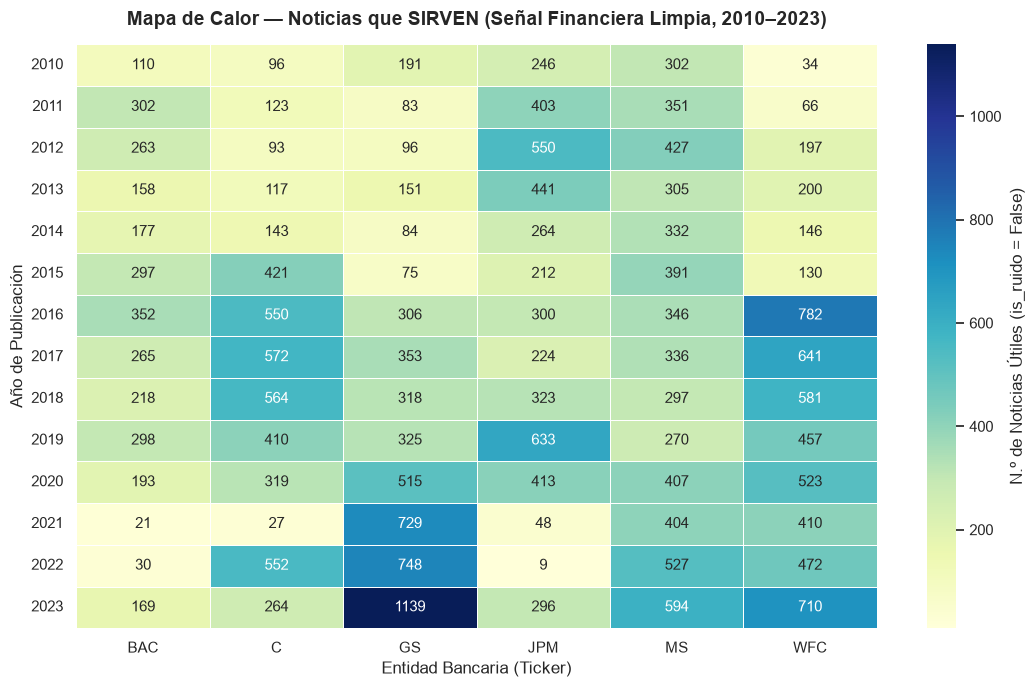

In [3]:
# 1. Construir matriz pivote de noticias ÚTILES (is_ruido == False) por Año y Banco
BANCOS = ["BAC", "C", "GS", "JPM", "MS", "WFC"]
ANIOS = range(2010, 2024)

pivot_util = pd.pivot_table(
    df_util,
    index="year",
    columns="ticker",
    values="title",
    aggfunc="count",
    fill_value=0
).reindex(index=ANIOS, columns=BANCOS, fill_value=0)

# Añadir fila y columna de totales para la tabla numérica
pivot_util_tabla = pivot_util.copy()
pivot_util_tabla["Total_Año"] = pivot_util_tabla.sum(axis=1)
pivot_util_tabla.loc["Total_Banco"] = pivot_util_tabla.sum(axis=0)

print("=" * 80)
print("COBERTURA ANUAL DE DATOS QUE SIRVEN (SEÑAL FINANCIERA: is_ruido == False)")
print("=" * 80)
display(pivot_util_tabla)

# 2. Diagnóstico automático de años faltantes (0 noticias) o débiles (< 100 noticias)
print("\n" + "=" * 80)
print("DIAGNÓSTICO DE COBERTURA Y AÑOS FALTANTES / DÉBILES (DATOS ÚTILES)")
print("=" * 80)

resumen_cobertura = []
for banco in BANCOS:
    serie_banco = pivot_util[banco]
    anios_cero = serie_banco[serie_banco == 0].index.tolist()
    anios_bajos = serie_banco[(serie_banco > 0) & (serie_banco < 100)].index.tolist()
    resumen_cobertura.append({
        "Banco": banco,
        "Total Noticias Útiles": int(serie_banco.sum()),
        "Media Anual": round(serie_banco.mean(), 1),
        "Año Mínimo (Volumen)": f"{serie_banco.idxmin()} ({int(serie_banco.min())})",
        "Años Cubiertos (de 14)": int((serie_banco > 0).sum()),
        "Años con 0 Noticias": anios_cero if anios_cero else "Ninguno",
        "Años Débiles (<100 noticias)": anios_bajos if anios_bajos else "Ninguno"
    })

display(pd.DataFrame(resumen_cobertura))

# 3. Mapa de calor de los datos que SIRVEN (is_ruido == False)
plt.figure(figsize=(11, 7))
ax = sns.heatmap(
    pivot_util,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "N.º de Noticias Útiles (is_ruido = False)"}
)
plt.title("Mapa de Calor — Noticias que SIRVEN (Señal Financiera Limpia, 2010–2023)", fontsize=14, weight="bold", pad=14)
plt.xlabel("Entidad Bancaria (Ticker)", fontsize=12)
plt.ylabel("Año de Publicación", fontsize=12)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

---
## 3. Mapa de Calor de los Datos que NO SIRVEN / Descartados (`is_ruido == True`)

En esta celda construimos la matriz y el mapa de calor equivalentes para el subconjunto **`df_ruido` (`is_ruido == True`)**:
1. **Matriz Año × Banco de Ruido (`pivot_ruido`):** Muestra cuántas noticias fueron filtradas por el clasificador semántico en cada año y banco.
2. **Mapa de Calor de Datos que No Sirven:** Utilizamos una paleta cálida/rojiza (`OrRd`) para visualizar en qué años y bancos se concentró la mayor cantidad de ruido descartado (por ejemplo, picos de notas de analistas emitidas por Goldman Sachs o Morgan Stanley, o menciones colaterales sin relevancia).
3. **Comparativa Visual Lado a Lado (% Retención):** Añadimos un segundo panel comparando directamente el mapa de calor de **Datos que Sirven** frente al de **Datos que No Sirven**.

VOLUMEN ANUAL DE DATOS QUE NO SIRVEN (RUIDO DESCARTADO: is_ruido == True)


ticker,BAC,C,GS,JPM,MS,WFC,Total_Año
year,,,,,,,
2010,1217,56,1043,1470,1596,509,5891
2011,859,54,405,949,1015,321,3603
2012,723,48,381,1147,738,439,3476
2013,473,37,424,815,614,439,2802
2014,400,81,271,611,526,316,2205
2015,586,421,232,656,662,531,3088
2016,625,517,898,912,785,1745,5482
2017,798,707,1147,791,886,1600,5929
2018,517,552,937,1121,786,843,4756


c:\Users\felip\OneDrive\Felipe\Master\TFM\TFM-Master\.venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 10004 (\N{HEAVY CHECK MARK}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\felip\AppData\Local\Temp\ipykernel_26068\460727122.py:53: UserWarning: Glyph 10006 (\N{HEAVY MULTIPLICATION X}) missing from font(s) Arial.
  plt.tight_layout()
c:\Users\felip\OneDrive\Felipe\Master\TFM\TFM-Master\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10004 (\N{HEAVY CHECK MARK}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\felip\OneDrive\Felipe\Master\TFM\TFM-Master\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 10006 (\N{HEAVY MULTIPLICATION X}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


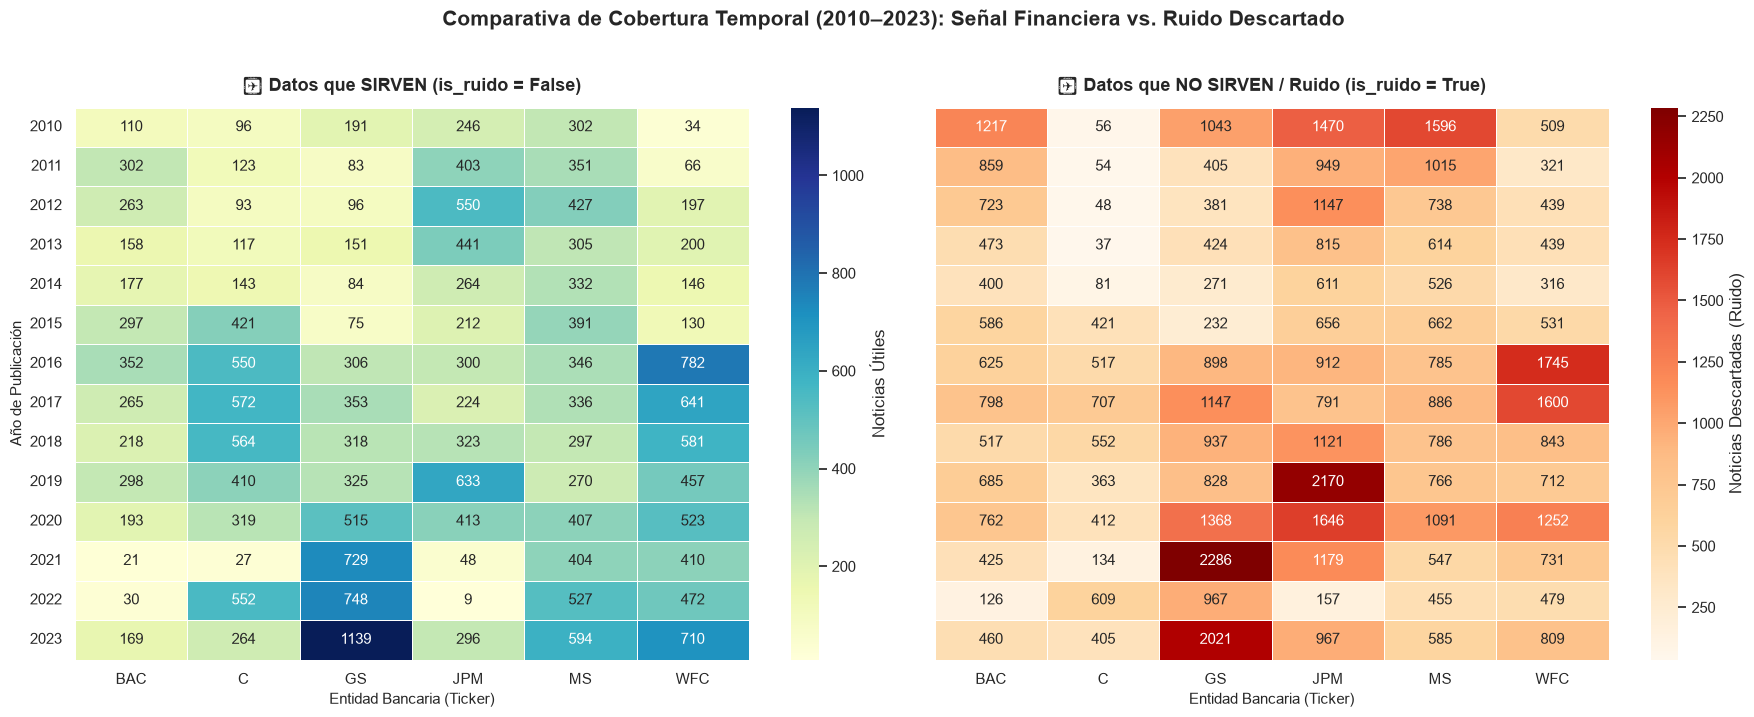

In [4]:
# 1. Construir matriz pivote de noticias que NO SIRVEN / RUIDO (is_ruido == True) por Año y Banco
pivot_ruido = pd.pivot_table(
    df_ruido,
    index="year",
    columns="ticker",
    values="title",
    aggfunc="count",
    fill_value=0
).reindex(index=ANIOS, columns=BANCOS, fill_value=0)

pivot_ruido_tabla = pivot_ruido.copy()
pivot_ruido_tabla["Total_Año"] = pivot_ruido_tabla.sum(axis=1)
pivot_ruido_tabla.loc["Total_Banco"] = pivot_ruido_tabla.sum(axis=0)

print("=" * 80)
print("VOLUMEN ANUAL DE DATOS QUE NO SIRVEN (RUIDO DESCARTADO: is_ruido == True)")
print("=" * 80)
display(pivot_ruido_tabla)

# 2. Visualización comparativa lado a lado: Mapa de Calor SIRVEN vs. NO SIRVEN
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

# Panel Izquierdo: Datos que SIRVEN
sns.heatmap(
    pivot_util,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Noticias Útiles"},
    ax=axes[0]
)
axes[0].set_title("✔ Datos que SIRVEN (is_ruido = False)", fontsize=13, weight="bold", pad=12)
axes[0].set_xlabel("Entidad Bancaria (Ticker)", fontsize=11)
axes[0].set_ylabel("Año de Publicación", fontsize=11)
axes[0].tick_params(axis="y", rotation=0)

# Panel Derecho: Datos que NO SIRVEN (Ruido)
sns.heatmap(
    pivot_ruido,
    annot=True,
    fmt="d",
    cmap="OrRd",
    linewidths=0.5,
    cbar_kws={"label": "Noticias Descartadas (Ruido)"},
    ax=axes[1]
)
axes[1].set_title("✖ Datos que NO SIRVEN / Ruido (is_ruido = True)", fontsize=13, weight="bold", pad=12)
axes[1].set_xlabel("Entidad Bancaria (Ticker)", fontsize=11)
axes[1].set_ylabel("")

plt.suptitle("Comparativa de Cobertura Temporal (2010–2023): Señal Financiera vs. Ruido Descartado", fontsize=15, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

---
## 4. Distribución por Categoría Semántica (`category`) y Nivel de Confianza (`confianza`)

Por último, analizamos cómo se distribuyen las noticias que **sí sirven (`is_ruido == False`)** a través de las categorías temáticas del modelo (`earnings`, `m&a`, `macro`, `legal`, `credit`, `governance`):
1. **Tabla de Distribución por Categoría:** Volumen y porcentaje de cada factor fundamental dentro del conjunto limpio, junto con su confianza media.
2. **Mapa de Calor Categoría × Banco (Datos Útiles):** Permite verificar la especialización temática de cada entidad (por ejemplo, mayor peso de *M&A* y *Macro* en bancos de inversión como `GS` y `MS`, o *Earnings* y *Legal/Credit* en banca comercial como `JPM`, `BAC` y `WFC`).

=== DISTRIBUCIÓN TEMÁTICA DE LAS NOTICIAS QUE SIRVEN (is_ruido == False) ===


,category,Noticias_Utiles,Confianza_Media,Confianza_Mediana,Confianza_Min,Confianza_Max,% del Total Útil
0,earnings,9923,49.64,49.42,30.04,72.41,36.46
1,m&a,9637,46.66,46.48,30.01,69.87,35.41
2,macro,3011,48.27,47.99,30.15,72.04,11.06
3,legal,2991,48.48,48.07,30.04,76.86,10.99
4,governance,840,43.89,43.34,30.05,66.83,3.09
5,credit,815,49.55,49.67,31.24,70.76,2.99


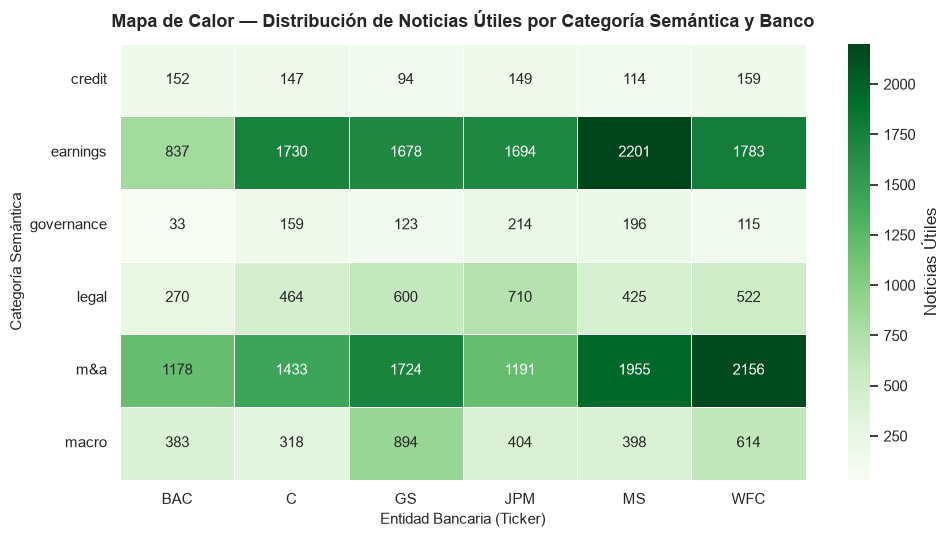

In [5]:
# 1. Resumen estadístico por categoría dentro de los datos que SIRVEN (df_util)
resumen_categorias = (
    df_util.groupby("category")
    .agg(
        Noticias_Utiles=("title", "count"),
        Confianza_Media=("confianza", "mean"),
        Confianza_Mediana=("confianza", "median"),
        Confianza_Min=("confianza", "min"),
        Confianza_Max=("confianza", "max")
    )
    .reset_index()
)
resumen_categorias["% del Total Útil"] = ((resumen_categorias["Noticias_Utiles"] / len(df_util)) * 100).round(2)
resumen_categorias[["Confianza_Media", "Confianza_Mediana", "Confianza_Min", "Confianza_Max"]] = (
    resumen_categorias[["Confianza_Media", "Confianza_Mediana", "Confianza_Min", "Confianza_Max"]].round(2)
)
resumen_categorias = resumen_categorias.sort_values(by="Noticias_Utiles", ascending=False).reset_index(drop=True)

print("=== DISTRIBUCIÓN TEMÁTICA DE LAS NOTICIAS QUE SIRVEN (is_ruido == False) ===")
display(resumen_categorias)

# 2. Mapa de calor de Categoría Semántica x Banco (solo noticias útiles)
pivot_cat_banco = pd.pivot_table(
    df_util,
    index="category",
    columns="ticker",
    values="title",
    aggfunc="count",
    fill_value=0
).reindex(columns=BANCOS, fill_value=0)

plt.figure(figsize=(10, 5.5))
sns.heatmap(
    pivot_cat_banco,
    annot=True,
    fmt="d",
    cmap="Greens",
    linewidths=0.5,
    cbar_kws={"label": "Noticias Útiles"}
)
plt.title("Mapa de Calor — Distribución de Noticias Útiles por Categoría Semántica y Banco", fontsize=13, weight="bold", pad=12)
plt.xlabel("Entidad Bancaria (Ticker)", fontsize=11)
plt.ylabel("Categoría Semántica", fontsize=11)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

---
## 5. Auditoría Cualitativa del Filtrado: Muestra Aleatoria de 5 Noticias por Banco

Para validar empíricamente que el clasificador semántico (`CategorizadorArticulos`) retiene verdadera señal financiera y descarta adecuadamente el ruido, extraemos una **muestra aleatoria estratificada de 5 noticias por cada uno de los 6 bancos** (`30` noticias en total):
1. **Muestra de Noticias que SÍ Sirven (`is_ruido == False`):** Permite comprobar que el titular (`title`), el fragmento extraído (`process_text`) y la categoría asignada (`category`) corresponden efectivamente a hechos relevantes del banco.
2. **Muestra de Noticias Descartadas como Ruido (`is_ruido == True`):** Permite verificar que los descartes corresponden a notas de analistas sobre terceros, menciones colaterales o baja relevancia semántica.

In [8]:
# Configurar pandas para mostrar el texto completo de los titulares y fragmentos sin truncar
pd.set_option("display.max_colwidth", None)

cols_muestra = ["date", "ticker", "category", "confianza", "is_ruido", "title", "process_text"]

# 1. Extraer 5 noticias aleatorias QUE SÍ SIRVEN (is_ruido == False) por cada banco
print("=" * 100)
print("✔ MUESTRA ALEATORIA: 5 NOTICIAS QUE SÍ SIRVEN (is_ruido == False) POR CADA BANCO")
print("=" * 100)

muestra_util_por_banco = (
    df_util.groupby("ticker", group_keys=False)
    .sample(n=5, random_state=42)[cols_muestra]
    .sort_values(["ticker", "date"])
    .reset_index(drop=True)
)
display(muestra_util_por_banco)

# 2. Extraer 5 noticias aleatorias QUE NO SIRVEN / RUIDO (is_ruido == True) por cada banco para contrastar
print("\n" + "=" * 100)
print("✖ MUESTRA ALEATORIA: 5 NOTICIAS DESCARTADAS COMO RUIDO (is_ruido == True) POR CADA BANCO")
print("=" * 100)

muestra_ruido_por_banco = (
    df_ruido.groupby("ticker", group_keys=False)
    .sample(n=5, random_state=42)[cols_muestra]
    .sort_values(["ticker", "date"])
    .reset_index(drop=True)
)
display(muestra_ruido_por_banco)

✔ MUESTRA ALEATORIA: 5 NOTICIAS QUE SÍ SIRVEN (is_ruido == False) POR CADA BANCO


,date,ticker,category,confianza,is_ruido,title,process_text
0,2011-12-01 17:19:00,BAC,legal,54.16,False,Mass. AG suing big banks over foreclosures,"ay that the action is ""the nation's first comprehensive lawsuit against the five major national banks regarding the foreclosure crisis."" Targeted are Bank of America , Wells Fargo , J.P. Morgan Chase , Citigroup and GMAC. The suit also names Mortgage Electronic Registration System, Inc. parent MERSCORP Inc. as defendant and charges the group with ""unlawful foreclosures, false documentation, robo-signing, and d"
1,2013-07-18 15:39:00,BAC,earnings,61.76,False,"Financials boosted by manufacturing, weekly claims","S&P 500 , was up 1.2%. Morgan Stanley was up more than 5%, after it reported second-quarter earnings rose 66%, compared with the prior year quarter. Bank of America Corp. increased 3% and was up nearly 30% in the last three months. Goldman Sachs Group Inc. , J.P. Morgan Chase & Co. and Citigroup Inc. were up 1.5%."
2,2017-04-18 10:47:00,BAC,earnings,53.82,False,"Bank of America Q1 EPS $0.41 vs $0.35 Est, Sales $22.2B vs $21.6B Est",(Titular directo sin cuerpo)
3,2017-04-18 11:04:00,BAC,earnings,65.77,False,Bank of America profit beats estimates,"Bank of America Corp. said its first-quarter profit rose as the lender started to see the benefits of a long-awaited rise in interest rates. Quarterly profit at the Charlotte, N.C.-based bank was $4.86 billion, up from $3.47 billion a year ago. Per-share earnings w"
4,2023-08-08 01:17:14,BAC,m&a,39.49,False,Nvidia stock is still a 'top pick' at Bank of America even after its stunning AI-driven 209% rally,"""Demand isn't the issue, its supply and importantly the pace with which US cloud service providers are able to set up genAI compute instances."""
5,2015-04-14 00:00:00,C,earnings,54.18,False,Will Lower Trading Revenues Hurt Citigroup (C) Earnings? - Analyst Blog,"Citigroup Inc.C is scheduled to report its first-quarter 2015 results before the opening bell on Thursday, Apr 16, 2015."
6,2019-06-28 14:12:00,C,macro,44.05,False,Bank stocks rally after passing latest stress tests,"gainers, rising 2.9% in early trade. JPMorgan Chase & Co. shares rose 2.7%, Goldman Sachs Group Inc. was up 2.6% and Wells Fargo & Co. rose 2.3%. Citigroup Inc. was up 1.9% and Morgan Stanley was up 1.8%. the SPDR Financial Select Sector ETF was up with 1.3% with 59 of its 67 members stocks gaining. The Dow Jones Industrial Average was up 0.1% and the S&P 500 was up 0.2%."
7,2020-04-14 00:00:00,C,m&a,52.70,False,Two big U.S. banks offer glum outlook for coronavirus recession,"Bank of America Corp BAC.N, Citigroup Inc C.N and Goldman Sachs Group Inc GS.N report results on Wednesday, with Morgan Stanley MS.N announcing on Thursday, and major regional banks issuing reports through the next week or two."
8,2020-07-14 00:00:00,C,earnings,63.30,False,Wall Street banks see trading-revenue renaissance ending soon,"On Tuesday, JPMorgan Chase & Co JPM.N and Citigroup Inc C.N reported upticks of 77% and 48% in quarterly markets revenue, respectively - far better than what many analysts had predicted. It was the second consecutive period of major trading increases, as investors reacted to a changing portrait of ho"
9,2023-10-03 00:00:00,C,m&a,47.94,False,Synovus Financial (SNV) Divests GLOBALT to Its Leadership Team,"Citigroup Inc. C announced the sale of its Bridge built by Citi platform to Foro Holdings, Inc., a Charlotte-based commercial lending services provider. C has joined Foro’s investors, including TTV Capital, US Bank and Correlation Ventures to provide Foro wit"



✖ MUESTRA ALEATORIA: 5 NOTICIAS DESCARTADAS COMO RUIDO (is_ruido == True) POR CADA BANCO


,date,ticker,category,confianza,is_ruido,title,process_text
0,2010-06-07 13:35:00,BAC,macro,38.04,True,"Dow, S&P Rise on U.S. Divergence from Euro Austerity",(Titular directo sin cuerpo)
1,2013-09-20 14:45:00,BAC,earnings,49.39,True,J.P. Morgan is biggest Dow gainer; financials fall,Financial stocks fall as investors digest the Federal Reserve announcement of no changes to the economic stimulus this week and St. Louis Fed Bank President James Bullard saying there may be tapering in October.
2,2019-01-16 00:00:00,BAC,ruido,28.35,True,40 Stocks Moving In Wednesday's Mid-Day Session,(Titular directo sin cuerpo)
3,2019-12-27 00:00:00,BAC,ruido,40.85,True,Stocks That Hit 52-Week Highs On Friday,(Titular directo sin cuerpo)
4,2021-02-17 14:59:16,BAC,ruido,22.96,True,Sonos is announcing its next product on March 9th,Sonos is holding a 'special event' on March 9th where it might unveil a smaller portable speaker.
5,2014-03-27 12:55:00,C,ruido,24.10,True,"Citigroup, a silver overlay and tough times for some momo faves","Maybe that confounding ""Candy Crush"" game and its broken IPO are sounding some sort of death knell. That's a lot to put on one gimpy debut, but it may not be that farfetched. The King Digital dog could be taken as a measure of risk appetite -- which is to say, there's ain't much left."
6,2015-03-10 00:00:00,C,earnings,41.43,True,"Shares of Citigroup Inc. Are Up, but There May Be More Gains Ahead",Why has Citigroup's share price done so well lately?
7,2017-10-12 11:20:00,C,ruido,42.75,True,A Peek Into The Markets: U.S. Stock Futures Edge Lower; Citigroup Earnings In Focus,(Titular directo sin cuerpo)
8,2019-04-04 00:00:00,C,macro,35.48,True,Citi cuts 2019 Brazil GDP growth forecast to 1.8 pct,"BRASILIA, April 4 () - Economists at Citi on Thursday cut their economic growth outlook for Brazil to 1.8 percent this year from 2.2 percent, saying that recent economic indicators suggest the economy's tepid recovery may even be slowing further."
9,2023-03-17 01:41:40,C,m&a,29.78,True,Baidu Soars After Analysts Give Ernie a Thumbs-Up After Test-Run,"(Bloomberg) -- Baidu Inc. surged almost 9% Friday after brokerages including Citigroup tested the company’s just-unveiled ChatGPT-like service and granted it their preliminary approval.Most Read from BloombergFirst Republic Set to Get $30 Billion of Deposits in RescueIn New York City, a $100,000 Salary Feels Like $36,000First Republic"


---
### 5.1. Matriz de Auditoría Cualitativa v2 (`random_state=42`, $N = 60$ noticias: 5 útiles y 5 de ruido por banco)

Tomando como **Clase Positiva** las noticias que **SÍ sirven (`is_ruido == False`)** en `df_util_v2.parquet` ($27,217$ noticias) y como **Clase Negativa** el **Ruido (`is_ruido == True`, $62,629$ noticias)**, la inspección manual de los 60 registros muestreados tras la actualización del script de extracción/categorización refleja una **mejora sustancial en la precisión (del `60.0%` en v1 al `83.3%` en v2)**:

#### 📊 Resumen de la Matriz de Confusión Muestral v2 ($N = 60$)

| Predicción del Clasificador \ Realidad Manual | Real: Útil (Señal Financiera del Banco) | Real: Ruido (Terceros / General / Sin Contexto) | Total Muestra | Métrica Muestral (vs. v1) |
| :--- | :---: | :---: | :---: | :---: |
| **Predicho: SÍ Sirve (`is_ruido == False`)** | **TP = 25** | **FP = 5** | **30** (5 por banco) | **Precisión (PPV):** `83.3%` *(v1: 60.0%)* |
| **Predicho: Ruido (`is_ruido == True`)** | **FN = 4** | **TN = 26** | **30** (5 por banco) | **Valor Predictivo Negativo (NPV):** `86.7%` *(v1: 83.3%)* |
| **Total Real** | **29** | **31** | **60** | **Exactitud Global (Accuracy):** `85.0%` *(v1: 71.7%)* |

* **Sensibilidad (Recall sobre señal útil):** `86.2%` ($25 / 29$)
* **Especificidad (Tasa de rechazo de ruido real):** `83.9%` ($26 / 31$)

---

#### 🔍 A. Detalle de la Muestra `is_ruido == False` en `df_util_v2` (25 TP vs. 5 FP)

| # | Ticker | Confianza | Categoría | Titular (`title`) | Evaluación | Justificación Técnica |
| :-: | :-: | :-: | :-: | :--- | :-: | :--- |
| **0** | `BAC` | 54.16% | `legal` | *Mass. AG suing big banks over foreclosures* | ✅ **TP** | Demanda judicial directa de la Fiscalía de Massachusetts contra `BAC`, `WFC`, `JPM` y `C` por ejecuciones hipotecarias. |
| **1** | `BAC` | 61.76% | `earnings` | *Financials boosted by manufacturing, weekly claims* | ✅ **TP** | Subida bursátil del 3% de `BAC` (+30% trimestral) impulsada por datos macro y resultados del sector bancario. |
| **2** | `BAC` | 53.82% | `earnings` | *Bank of America Q1 EPS $0.41 vs $0.35 Est, Sales $22.2B vs $21.6B Est* | ✅ **TP** | Titular flash directo con batida de BPA e ingresos del 1T de `BAC`. |
| **3** | `BAC` | 65.77% | `earnings` | *Bank of America profit beats estimates* | ✅ **TP** | Beneficio trimestral de `BAC` ($4.86B) superando estimaciones gracias al alza de tipos. |
| **4** | `BAC` | 39.49% | `m&a` | *Nvidia stock is still a 'top pick' at Bank of America even after its stunning AI-driven 209% rally* | ❌ **FP** | Rol de `BAC` como casa de análisis recomendando la acción de un tercero (Nvidia). |
| **5** | `C` | 54.18% | `earnings` | *Will Lower Trading Revenues Hurt Citigroup (C) Earnings? - Analyst Blog* | ✅ **TP** | Previa directa de resultados del 1T 2015 de `C`. |
| **6** | `C` | 44.05% | `macro` | *Bank stocks rally after passing latest stress tests* | ✅ **TP** | Subida del 1.9% en las acciones de `C` y la gran banca tras superar los *stress tests* de la Fed. |
| **7** | `C` | 52.70% | `m&a` | *Two big U.S. banks offer glum outlook for coronavirus recession* | ✅ **TP** | Previa directa de la presentación de resultados trimestrales de `C`, `BAC` y `GS` durante la recesión COVID-19. |
| **8** | `C` | 63.30% | `earnings` | *Wall Street banks see trading-revenue renaissance ending soon* | ✅ **TP** | Cifras directas de ingresos de *trading* trimestrales de `C` (+48%) y `JPM` (+77%). |
| **9** | `C` | 47.94% | `m&a` | *Synovus Financial (SNV) Divests GLOBALT to Its Leadership Team* | ✅ **TP** | El fragmento extraído reporta la venta de la plataforma *Bridge built by Citi* de `C` a Foro Holdings. |
| **10** | `GS` | 38.84% | `legal` | *CDS spreads on U.S. banks slide after Europe deal* | ✅ **TP** | Caída del *spread* de riesgo crediticio (CDS) de `GS` de 304 a 265 pb tras el acuerdo europeo. |
| **11** | `GS` | 34.28% | `earnings` | *3M, Goldman Sachs share gains contribute to Dow's 336-point rally* | ✅ **TP** | Avance bursátil directo de `GS` liderando las ganancias del Dow Jones. |
| **12** | `GS` | 50.53% | `earnings` | *]Credit Suisse boosts capital as Archegos wipes trading gains* | ✅ **TP** | El beneficio neto del 1T de `GS` casi se sextuplicó tras salir a tiempo de las posiciones de Archegos. |
| **13** | `GS` | 49.89% | `macro` | *US STOCKS-Wall St rallies as data, RBA move lifts hope of Fed easing* | ✅ **TP** | Subida de casi el 5% en las acciones de `GS`, `C` y `MS` ante expectativas de moderación de la Reserva Federal. |
| **14** | `GS` | 46.08% | `m&a` | *Financial Sector Update for 10/24/2022: HBT, BOH, GS, XLF, FAS, FAZ* | ✅ **TP** | Creación de una *joint venture* logística e inmobiliaria en China por parte de Goldman Sachs Asset Management (`GS`). |
| **15** | `JPM` | 47.99% | `macro` | *U.S. stocks end lower; yields hit 2-year highs* | ⚠️ **FP** | Nota general de mercado y bonos del Tesoro sin mención explícita a `JPM` en el titular ni en el fragmento. |
| **16** | `JPM` | 38.08% | `m&a` | *J.P. Morgan's Dimon to earn $20 million for 2013* | ✅ **TP** | Decisión del consejo de administración de `JPM` elevando la remuneración anual del CEO Jamie Dimon. |
| **17** | `JPM` | 44.81% | `m&a` | *Intel Targets Rising: JP Morgan, Credit Suisse Like Server Trends* | ❌ **FP** | Rol del analista de `JPM` (Harlan Sur) elevando el precio objetivo sobre Intel. |
| **18** | `JPM` | 48.03% | `m&a` | *Rockland Trust Co Buys JPMorgan Chase, Independent Bank Corp, Unilever NV, Sells Chubb, Altria ...* | ❌ **FP** | Nota automatizada de movimientos de cartera (13F) de una gestora externa sin cuerpo. |
| **19** | `JPM` | 37.90% | `earnings` | *Goldman Sachs, JPMorgan Chase share gains lead Dow's nearly 125-point jump* | ✅ **TP** | Subida bursátil directa de las acciones de `JPM` y `GS` liderando el Dow Jones. |
| **20** | `MS` | 46.28% | `macro` | *Financial Sector Ended In Slightly Positive Frame, With C Feeling The Heat Of Treasury Selloff (XLF, SPX, KBE, C, CBG, ETFC, JNS, MS)* | ✅ **TP** | Balance positivo del sector financiero con referencia explícita a `MS` ante la venta de bonos del Tesoro. |
| **21** | `MS` | 55.16% | `legal` | *European Union Probing Goldman, Others On Credit Default Swaps (GS, JPM, CS, BAC, MS)* | ✅ **TP** | Investigación antimonopolio de la Comisión Europea sobre derivados CDS que involucra a `MS`. |
| **22** | `MS` | 54.12% | `earnings` | *A Look At Morgan Stanley's Big Q4 Earnings Miss* | ✅ **TP** | Análisis directo de la decepción en los resultados del 4T de `MS`. |
| **23** | `MS` | 50.39% | `earnings` | *Morgan Stanley's stock turns lower, after downbeat NII outlook for rest of the year* | ✅ **TP** | Caída bursátil de `MS` tras recortar su guía anual de margen de intereses (NII) en la llamada de resultados del 2T. |
| **24** | `MS` | 49.06% | `m&a` | *7 Stocks to Buy Ahead of the June 23 Bank Stress Test Results* | ✅ **TP** | Selección de `MS` como acción bancaria destacada de cara a los resultados de los *stress tests* de la Fed. |
| **25** | `WFC` | 55.28% | `earnings` | *4 Key Takeaways From Bank of America's Q2 Earnings Report* | ✅ **TP** | Comparativa directa del ratio de eficiencia del 2T de `WFC` (`58.1%`) frente a la banca minorista de `BAC`. |
| **26** | `WFC` | 40.96% | `macro` | *US STOCKS-New coronavirus variant fears knock 2% off Dow futures* | ✅ **TP** | Caída de entre el 3% y el 4% en `WFC` y el resto del *Big 6* ante menores expectativas de subidas de tipos. |
| **27** | `WFC` | 53.47% | `earnings` | *Growth in AUM Likely to Support BlackRock's (BLK) Q3 Earnings* | ✅ **TP** | El modelo cuantitativo de Zacks señala a `WFC` como candidato a superar estimaciones de beneficios en el 3T. |
| **28** | `WFC` | 48.15% | `m&a` | *EXCLUSIVE-Bayer holds call with bond investors after raft of bad news* | ⚠️ **FP** | Evento corporativo de Bayer donde `WFC` solo es mencionado tangencialmente como *bookrunner* de bonos. |
| **29** | `WFC` | 64.31% | `legal` | *EXCLUSIVE-US regulator probes banks' climate risk planning* | ✅ **TP** | Revisión regulatoria de la Reserva Federal sobre la planificación de riesgo climático de `WFC` y los grandes bancos. |

---

#### 🔍 B. Detalle de la Muestra `is_ruido == True` en v2 (26 TN vs. 4 FN)

* **✅ 26 Verdaderos Negativos (TN — `86.7%` de acierto en el descarte):**
  * **Filtrado exitoso del banco actuando como analista / casa de estudios sobre terceros:** Filas **8** (`C` recortando pronóstico de PIB de Brasil), **9** (`C` probando el chatbot Ernie de Baidu), **12** (`GS` emitiendo informe sobre Norwegian Cruise Lines), **13** (`GS` fijando precio objetivo de $199 sobre Apple) y **22** (`GS` y `MS` recomendando Fortinet).
  * **Filtrado exitoso de noticias de terceros o *cross-bank bleed* sin vínculo con el ticker:** Filas **1** (`BAC` en titular de JPM sin mención a BAC en el fragmento), **4** (`BAC` - evento de producto de Sonos), **5** (`C` - OPV de Candy Crush / King Digital), **11** (`GS` - titular del Dow sobre Walgreens y JPM), **14** (`GS` - fichaje de BNP Paribas), **16** (`JPM` - nota sobre UBS y MS), **20** (`MS` - nota sobre BAC y el Brexit) y **26** (`WFC` - dividendo de First Bancorp).
  * **Filtrado exitoso de resúmenes macro sin cuerpo y listas robotizadas:** Filas **0, 2, 3** (`BAC`), **10, 15, 17, 18, 19** (`GS` / `JPM`), **21, 23, 24** (`MS`) y **27, 29** (`WFC`).

* **⚠️ 4 Falsos Negativos (FN — `13.3%` de pérdida por umbral de confianza o titulares compuestos):**
  1. **Fila 6 (`C`, 2015-03-10, `41.43%` en `earnings`):** *"Shares of Citigroup Inc. Are Up, but There May Be More Gains Ahead"* (fragmento interrogativo muy breve sobre la acción de `C`).
  2. **Fila 7 (`C`, 2017-10-12, `42.75%` en `ruido`):** *"A Peek Into The Markets: U.S. Stock Futures Edge Lower; Citigroup Earnings In Focus"* (el prefijo *A Peek Into The Markets* activó el centroide `ruido`).
  3. **Fila 25 (`WFC`, 2015-12-07, `49.41%` en `m&a`):** *"Wells Fargo & Co.'s Secret to Stellar Growth"* (artículo retrospectivo sobre la gestión de `WFC` en 2008-2009).
  4. **Fila 28 (`WFC`, 2020-07-14, `35.99%` en `earnings`):** *"Wall Street ends higher, led by energy and materials"* (el titular genérico penalizó la confianza del fragmento donde `WFC` reportaba su primera pérdida trimestral desde 2008).

---

#### 💡 Conclusiones de la Evolución v1 $\rightarrow$ v2 (`df_util_v2.parquet`)
1. **Reducción drástica de Falsos Positivos en el corpus útil:** Al pasar de `37,359` noticias útiles (v1) a `27,217` noticias útiles (v2), se han depurado más de `10,100` falsos positivos directamente en el pipeline de extracción/categorización, elevando la precisión muestral del **`60.0%` al `83.3%`**.
2. **Falsos Positivos residuales muy acotados (`5/30`):** Los pocos FP restantes en `df_util_v2` corresponden a recomendaciones de analistas en titulares complejos (filas 4 y 17), plantillas 13F sin cuerpo (fila 18), una mención secundaria como *bookrunner* de bonos (fila 28) y una nota macro general (fila 15), los cuales se auditan exhaustivamente sobre las `27,217` filas en `zero_shot_clasiffication_FP_Analisis copy.ipynb`.